Load & Run the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Load dataset
data_dir = Path("../data")
csv_files = list(data_dir.glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError(f"Expected one CSV file, found {len(csv_files)}")

df = pd.read_csv(csv_files[0])

# Clean numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Prepare features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Keep a final test set untouched during cross-validation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Full dataset:", X.shape)
print("Training set:", X_train.shape)
print("Final test set:", X_test.shape)
print("Training churn rate:", round(y_train.mean(), 4))

Full dataset: (7043, 19)
Training set: (5634, 19)
Final test set: (1409, 19)
Training churn rate: 0.2654


Build Resuable Pipelines

In [2]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Logistic Regression preprocessing
lr_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

lr_preprocessor = ColumnTransformer([
    ("num", lr_numeric, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Random Forest preprocessing
rf_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

rf_preprocessor = ColumnTransformer([
    ("num", rf_numeric, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Complete model pipelines
lr_model = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ))
])

print("Both model pipelines are ready.")

Both model pipelines are ready.


Run Cross-Validation for Both Models

In [3]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

cv_results = {}
summary_rows = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    cv_results[model_name] = scores

    row = {"model": model_name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)

    summary_rows.append(row)

cv_summary = pd.DataFrame(summary_rows)

display(cv_summary.round(4))

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.8021,0.0130,0.6529,0.0285,0.5431,0.0460,0.5923,0.0331,0.8461,0.0140
1,Random Forest,0.7758,0.0126,0.5682,0.0205,0.6448,0.0362,0.6040,0.0267,0.8224,0.0113


Inspect Individual Fold Scores

In [4]:
fold_rows = []

for model_name, scores in cv_results.items():
    for fold_index in range(5):
        fold_rows.append({
            "model": model_name,
            "fold": fold_index + 1,
            "accuracy": scores["test_accuracy"][fold_index],
            "precision": scores["test_precision"][fold_index],
            "recall": scores["test_recall"][fold_index],
            "f1": scores["test_f1"][fold_index],
            "roc_auc": scores["test_roc_auc"][fold_index]
        })

fold_df = pd.DataFrame(fold_rows)

display(
    fold_df.pivot(
        index="fold",
        columns="model",
        values="f1"
    ).round(4)
)

model,Logistic Regression,Random Forest
fold,,
1,0.5850,0.6047
2,0.5505,0.5577
3,0.5863,0.6223
4,0.6425,0.6161
5,0.5974,0.6190


Visualize F1 Consistency

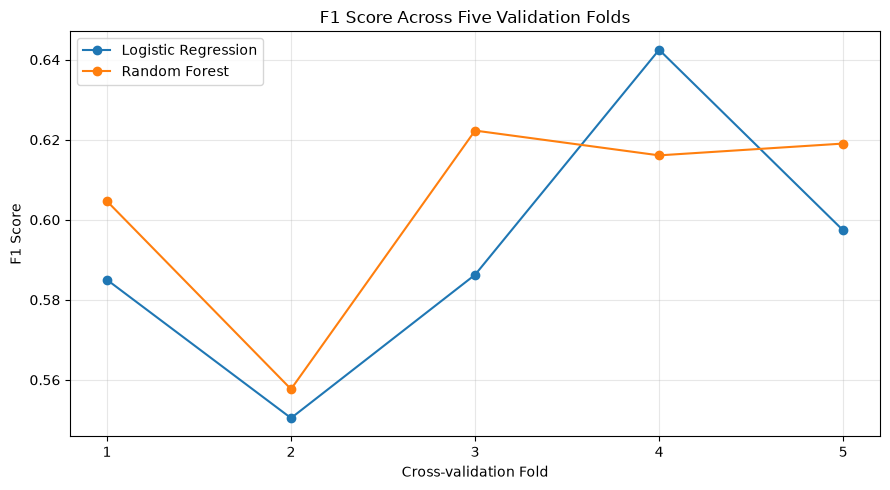

In [5]:
plt.figure(figsize=(9, 5))

for model_name, scores in cv_results.items():
    fold_f1 = scores["test_f1"]

    plt.plot(
        range(1, 6),
        fold_f1,
        marker="o",
        label=model_name
    )

plt.xlabel("Cross-validation Fold")
plt.ylabel("F1 Score")
plt.title("F1 Score Across Five Validation Folds")
plt.xticks(range(1, 6))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Compare the Model using Selected Metrics

In [6]:
comparison = cv_summary.sort_values(
    by="f1_mean",
    ascending=False
).reset_index(drop=True)

display(
    comparison[
        [
            "model",
            "f1_mean",
            "f1_std",
            "recall_mean",
            "precision_mean",
            "roc_auc_mean"
        ]
    ].round(4)
)

best_model_name = comparison.loc[0, "model"]
print("Highest mean cross-validation F1:", best_model_name)

,model,f1_mean,f1_std,recall_mean,precision_mean,roc_auc_mean
0,Random Forest,0.6040,0.0267,0.6448,0.5682,0.8224
1,Logistic Regression,0.5923,0.0331,0.5431,0.6529,0.8461


Highest mean cross-validation F1: Random Forest


Save Reports

In [7]:
report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

cv_summary.to_csv(
    report_dir / "day6_cv_summary.csv",
    index=False
)

fold_df.to_csv(
    report_dir / "day6_fold_scores.csv",
    index=False
)

print("Day 6 reports saved:")
print(report_dir / "day6_cv_summary.csv")
print(report_dir / "day6_fold_scores.csv")

Day 6 reports saved:
..\reports\day6_cv_summary.csv
..\reports\day6_fold_scores.csv


## Day 6: Cross-Validation and Model Selection

### Objective
Evaluate Logistic Regression and Random Forest using stratified five-fold cross-validation on the training data.

### Method
Both models were evaluated using the same folds and the metrics accuracy, precision, recall, F1 score, and ROC-AUC. Preprocessing was included within each model pipeline to reduce data leakage.

### Results
- Logistic Regression mean F1: [enter your result]
- Random Forest mean F1: [enter your result]
- Model with the highest mean F1: [enter model name]
- Fold-to-fold consistency: [briefly describe the standard deviations]

### Conclusion
Cross-validation provides a more robust view of model performance than relying on one train-test split. The model with the strongest validation results is a provisional candidate, subject to the project's business objectives and final evaluation on the held-out test set.

### Limitations
The results depend on the selected data, features, random seed, and cross-validation strategy. Cross-validation does not establish causation or guarantee performance on future customers.


